# Dynamite Plot vs. Points + Confidence Interval

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

A "dynamite plot" (bar of the mean plus a standard-error whisker) shows only two numbers per group and hides the data. Groups with the same mean but completely different distributions (bimodal, skewed, with outliers, tiny n) look identical. The bar also suggests that values fill the area from zero up to the mean, which they do not, and SE whiskers are routinely misread as data spread or as confidence intervals.

## When to use

- Show the raw data points (jittered or beeswarm) with the mean and 95% CI on top for small-to-moderate n
- Use box, violin or raincloud plots for larger samples
- State the interval type and n in the chart

## Avoid when

- Bar charts of means for continuous measurements, common in lab and clinical papers
- Error bars without saying whether they are SD, SE or CI

## Alternatives

- Strip / beeswarm plot with mean ± 95% CI
- Box plot or raincloud plot
- Estimation plot (effect size with CI)

## Design tips

- Prefer 95% CI over SE; label it explicitly ("mean ± 95% CI")
- Annotate n per group
- Bars are for counts and totals, not for means of continuous data

## Example

A biomarker measured in two treatment groups of 30 patients, with the same mean but a unimodal vs. a bimodal response.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy import stats

### Data

In [2]:
rng = np.random.default_rng(30)
a = rng.normal(50, 8, 30)
b = np.concatenate([rng.normal(30, 5, 15), rng.normal(70, 5, 15)])
b = b - b.mean() + a.mean()   # force identical means
df = pd.DataFrame({"group": ["Treatment A"] * 30 + ["Treatment B"] * 30,
                   "value": np.concatenate([a, b])})
df.groupby("group")["value"].agg(["count", "mean", "std", "sem"]).round(1)

,count,mean,std,sem
group,,,,
Treatment A,30,51.2,7.6,1.4
Treatment B,30,51.2,21.4,3.9


### Plot

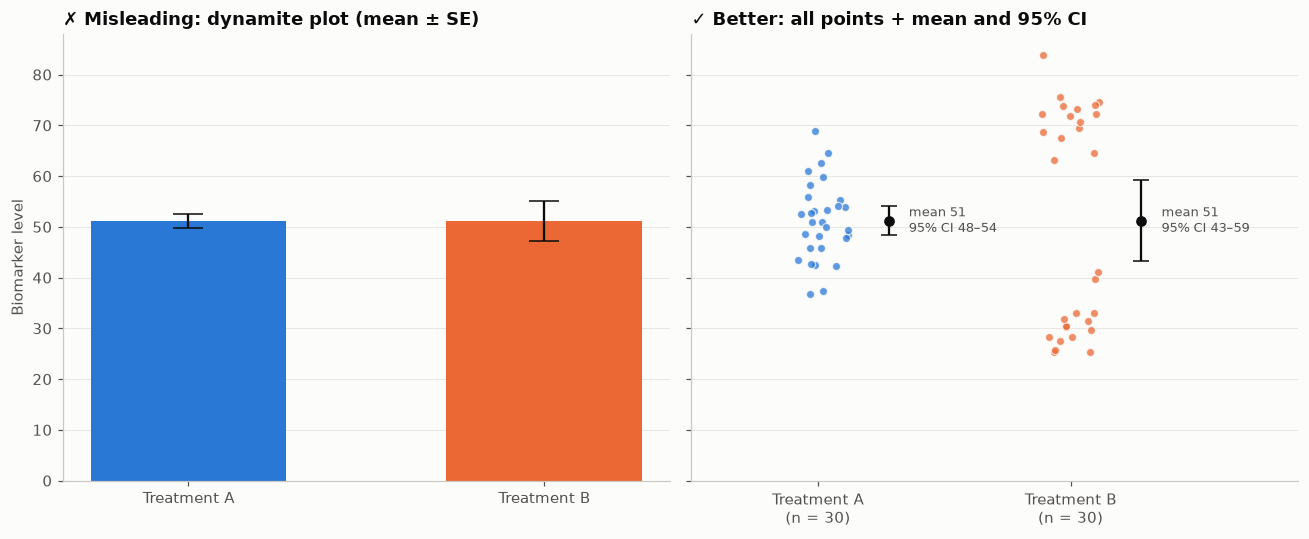

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
groups = ["Treatment A", "Treatment B"]
summary = df.groupby("group")["value"].agg(["mean", "sem", "count"]).loc[groups]

# Misleading: bar of means + SE whisker.
ax1.bar(groups, summary["mean"], yerr=summary["sem"], color=[PALETTE[0], PALETTE[1]],
        width=0.55, capsize=10, error_kw=dict(elinewidth=1.5, ecolor="#0b0b0b"))
ax1.set_ylabel("Biomarker level")
ax1.set_title("✗ Misleading: dynamite plot (mean ± SE)", fontsize=11.5)
ax1.grid(axis="x", visible=False)

# Better: every point + mean and 95% CI, n labeled.
for i, g in enumerate(groups):
    vals = df.loc[df["group"] == g, "value"].to_numpy()
    jitter = rng.uniform(-0.12, 0.12, len(vals))
    ax2.scatter(i + jitter, vals, s=28, color=PALETTE[i], alpha=0.75,
                edgecolor="#fcfcfb", linewidth=0.8, zorder=2)
    m = vals.mean()
    lo, hi = stats.t.interval(0.95, len(vals) - 1, loc=m, scale=stats.sem(vals))
    ax2.errorbar(i + 0.28, m, yerr=[[m - lo], [hi - m]], fmt="o", color="#0b0b0b",
                 capsize=5, markersize=6, linewidth=1.5, zorder=3)
    ax2.text(i + 0.36, m, f"mean {m:.0f}\n95% CI {lo:.0f}–{hi:.0f}", va="center", fontsize=8.5,
             color="#52514e")
ax2.set_xticks([0, 1], [f"{g}\n(n = {int(summary.loc[g, 'count'])})" for g in groups])
ax2.set_xlim(-0.5, 1.9)
ax2.set_title("✓ Better: all points + mean and 95% CI", fontsize=11.5)
ax2.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

On the left the two treatments look identical. On the right, Treatment B splits patients into two groups, responders and non-responders, which is a completely different clinical story that the bars hide.

---
Standalone script: [`dynamite_plot.py`](dynamite_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)